# Analisi esplorativa della serie oraria

Questo notebook guarda i dati *prima* del modello e risponde a tre domande che
altrove nel progetto sono date per buone:

1. **Perché i lag 24 e 168?** Si vedono nell'autocorrelazione, non si decidono a tavolino.
2. **Perché il test dura 12 mesi e non 6?** Lo dice la stagionalità annuale.
3. **Perché si valuta l'88,9 % delle ore di test e non il 98,7 %?** Perché un'ora
   mancante ne squalifica fino a 169, ed è un effetto che va misurato.

Le feature non vengono ricostruite qui: il notebook importa `energy.features.build`,
lo stesso modulo usato dal training e dall'API. Se le feature cambiano, cambia anche
questa analisi — che è esattamente il comportamento voluto.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# Il notebook vive in notebooks/, ma la pipeline usa percorsi relativi alla radice
# del progetto (configs/params.yaml, data/processed/...). Ci si sposta una volta sola.
ROOT = Path.cwd()
while not (ROOT / "configs" / "params.yaml").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
os.chdir(ROOT)

# Il pacchetto e' installato con `pip install -e .`; questa riga lo rende
# importabile anche da un kernel che non vede l'ambiente virtuale del progetto.
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from energy.config import load_params  # noqa: E402
from energy.evaluation import is_test, split_date  # noqa: E402
from energy.features.build import build_features, supervised_for_horizon  # noqa: E402

# Palette del progetto: gli stessi due colori della dashboard, piu' una rampa
# monotona in luminosita' per le mappe di calore.
BLU, ARANCIO = "#2a78d6", "#eb6834"
RAMPA = ["#d6e4f7", "#9cc0ec", "#5b97e0", "#2a78d6", "#1b4f8f"]
BLU_SEQ = LinearSegmentedColormap.from_list("blu_seq", RAMPA)
INCHIOSTRO, TENUE = "#3c4043", "#80868b"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c9ccd1",
        "axes.labelcolor": INCHIOSTRO,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#dfe1e5",
        "grid.linewidth": 0.6,
        "text.color": INCHIOSTRO,
        "xtick.color": TENUE,
        "ytick.color": TENUE,
        "legend.frameon": False,
        "lines.linewidth": 2.0,
    }
)

print("radice del progetto:", ROOT)

radice del progetto: c:\energy-forecasting-mlops


In [2]:
params = load_params()

TARGET = params["data"]["target"]
LAGS = params["features"]["lags"]
FINESTRE = params["features"]["rolling_windows"]
TEST_MESI = params["split"]["test_months"]

# Ampiezza della finestra storica necessaria a una riga completa: il lag piu'
# lontano, oppure la media mobile piu' lunga, piu' l'ora corrente.
AMPIEZZA = max(max(LAGS), max(FINESTRE) - 1) + 1

grezzo = pd.read_parquet(params["data"]["processed_path"])
if not isinstance(grezzo.index, pd.DatetimeIndex):
    raise TypeError("l'indice del parquet non e' temporale: controlla create_dataset.py")
grezzo = grezzo.sort_index()
serie = grezzo[TARGET]

STACCO = split_date(serie.index, TEST_MESI)

print(f"target          : {TARGET}")
print(f"lag             : {LAGS}")
print(f"medie mobili    : {FINESTRE}")
print(f"finestra storica: {AMPIEZZA} ore")
print(f"inizio del test : {STACCO + pd.Timedelta(hours=1)}")

target          : global_active_power
lag             : [0, 1, 2, 3, 24, 25, 48, 168]
medie mobili    : [24, 168]
finestra storica: 169 ore
inizio del test : 2009-11-26 22:00:00


## 1. Panoramica della serie

In [3]:
riassunto = pd.Series(
    {
        "prima ora": serie.index.min(),
        "ultima ora": serie.index.max(),
        "ore nell'intervallo": len(serie),
        "ore osservate": int(serie.notna().sum()),
        "ore mancanti": int(serie.isna().sum()),
        "quota mancante": f"{serie.isna().mean():.2%}",
        "media (kW)": round(float(serie.mean()), 3),
        "mediana (kW)": round(float(serie.median()), 3),
        "95esimo percentile (kW)": round(float(serie.quantile(0.95)), 3),
        "massimo (kW)": round(float(serie.max()), 3),
    }
)
riassunto.to_frame("valore")

,valore
prima ora,2006-12-16 17:00:00
ultima ora,2010-11-26 21:00:00
ore nell'intervallo,34589
ore osservate,34151
ore mancanti,438
quota mancante,1.27%
media (kW),1.092
mediana (kW),0.803
95esimo percentile (kW),2.866
massimo (kW),6.561


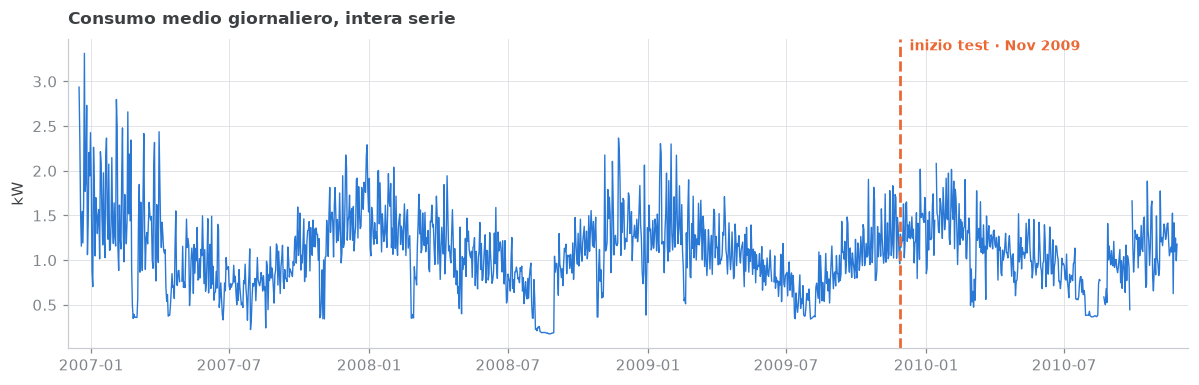

In [4]:
giornaliero = serie.resample("D").mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(giornaliero.index, giornaliero.to_numpy(), color=BLU, linewidth=0.9)
ax.axvline(STACCO, color=ARANCIO, linestyle="--", linewidth=1.8)
ax.set_title("Consumo medio giornaliero, intera serie")
ax.set_ylabel("kW")
ax.margins(x=0.01)
ax.text(
    STACCO,
    ax.get_ylim()[1],
    f"  inizio test · {STACCO:%b %Y}",
    color=ARANCIO,
    va="top",
    ha="left",
    fontsize=9,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

La media giornaliera rende leggibile il ciclo annuale: inverni alti, estati basse,
con un avvallamento netto ad agosto che è quasi certamente un periodo di assenza.
La linea arancione segna l'inizio dei 12 mesi di test.

## 2. Dati mancanti, e perché costano più di quanto sembri

In [5]:
mancanti = serie.isna()
blocchi = mancanti.ne(mancanti.shift()).cumsum()[mancanti]
lunghezze = mancanti[mancanti].groupby(blocchi).size()

distribuzione = (
    pd.cut(
        lunghezze,
        bins=[0, 1, 3, 6, 12, 24, 10**6],
        labels=["1 ora", "2-3 ore", "4-6 ore", "7-12 ore", "13-24 ore", "oltre 24 ore"],
    )
    .value_counts()
    .sort_index()
    .rename("numero di buchi")
    .rename_axis("lunghezza del buco")
)

print(f"buchi distinti : {len(lunghezze)}")
print(f"ore perse      : {int(lunghezze.sum())}")
print(f"buco piu' lungo: {int(lunghezze.max())} ore")
distribuzione.to_frame()

buchi distinti : 16
ore perse      : 438
buco piu' lungo: 121 ore


,numero di buchi
lunghezza del buco,
1 ora,8
2-3 ore,1
4-6 ore,0
7-12 ore,0
13-24 ore,1
oltre 24 ore,6


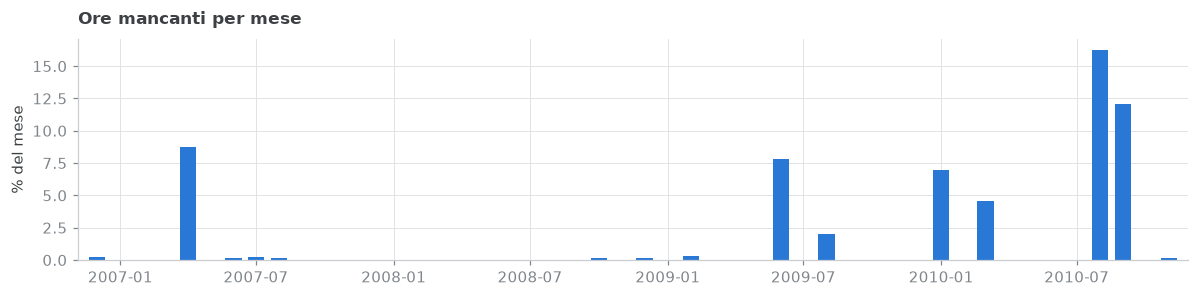

In [6]:
per_mese = mancanti.resample("MS").mean()

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(per_mese.index, per_mese.to_numpy() * 100, width=22, color=BLU)
ax.set_title("Ore mancanti per mese")
ax.set_ylabel("% del mese")
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

In [7]:
# Una riga e' utilizzabile solo se la finestra storica che la precede e' completa
# e se il target a t+h e' osservato. Un'ora mancante ne invalida fino ad AMPIEZZA.
osservata = serie.notna()
finestra_piena = osservata.rolling(AMPIEZZA, min_periods=AMPIEZZA).sum().eq(AMPIEZZA)

# Ore di test: quelle successive allo stacco. Non dipende dall'orizzonte, ed e'
# lo stesso denominatore con cui energy.models.baseline calcola la copertura.
ORE_TEST = int((serie.index > STACCO).sum())

righe = []
for h in (1, 24):
    bersaglio = osservata.shift(-h).fillna(False).astype(bool)
    nel_test = pd.Series(is_test(serie.index, h, STACCO), index=serie.index)
    valutabili = int((nel_test & bersaglio & finestra_piena).sum())
    righe.append(
        {
            "orizzonte": h,
            "ore di test": ORE_TEST,
            "ore valutabili": valutabili,
            "copertura": round(valutabili / ORE_TEST, 4),
        }
    )

confronto = pd.DataFrame(righe).set_index("orizzonte")

# Controllo incrociato con i numeri prodotti dalla pipeline.
percorso = Path("reports/baseline_metrics.json")
if percorso.exists():
    pipeline = json.loads(percorso.read_text(encoding="utf-8"))["horizons"]
    confronto["pipeline"] = [pipeline[str(h)]["test_hours_evaluated"] for h in confronto.index]
    confronto["coincide"] = confronto["ore valutabili"] == confronto["pipeline"]

confronto

,ore di test,ore valutabili,copertura,pipeline,coincide
orizzonte,,,,,
1,8760,7789,0.8892,7789,True
24,8760,7697,0.8787,7697,True


Qui sta il punto. Le ore mancanti sono una frazione minima della serie, ma la
copertura del test scende molto più di quella frazione: ogni buco si propaga in
avanti per l'intera finestra storica, perché finché il buco resta dentro le ultime
`AMPIEZZA` ore la riga non ha feature complete.

La colonna `coincide` confronta il conteggio appena fatto con quello scritto da
`energy.models.baseline`. Se è `True`, questa analisi e la pipeline stanno contando
le stesse ore — ed è l'unico modo serio di verificare che i baseline del README si
riferiscano davvero all'insieme di valutazione dichiarato.

## 3. Profilo giornaliero e settimanale

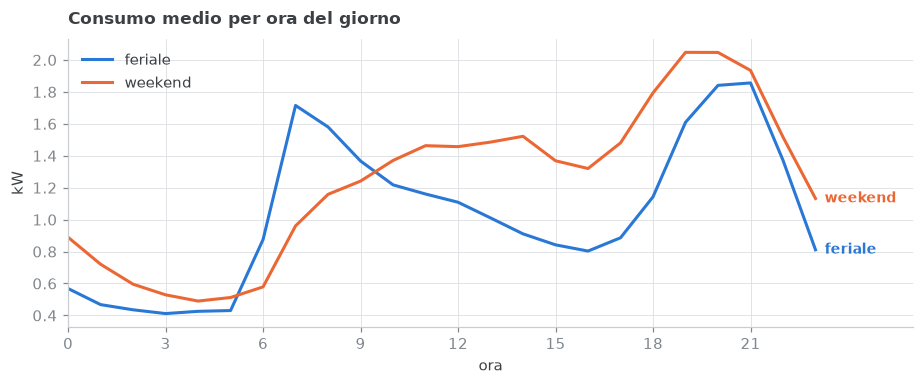

In [8]:
feriali = serie.index.dayofweek < 5
profilo = pd.DataFrame(
    {
        "feriale": serie[feriali].groupby(serie.index[feriali].hour).mean(),
        "weekend": serie[~feriali].groupby(serie.index[~feriali].hour).mean(),
    }
)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
for nome, colore in (("feriale", BLU), ("weekend", ARANCIO)):
    ax.plot(profilo.index, profilo[nome].to_numpy(), color=colore, label=nome)
    ax.annotate(
        nome,
        xy=(23, profilo[nome].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        color=colore,
        fontsize=9,
        fontweight="bold",
        va="center",
    )
ax.set_title("Consumo medio per ora del giorno")
ax.set_xlabel("ora")
ax.set_ylabel("kW")
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(0, 26)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

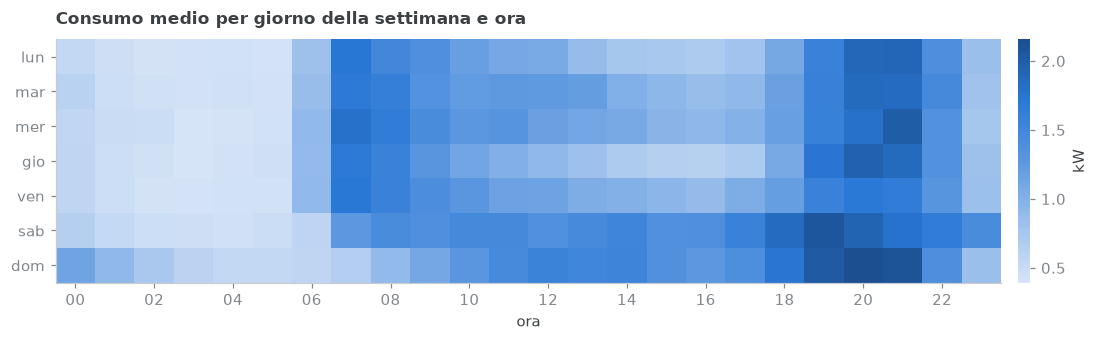

In [9]:
matrice = serie.groupby([serie.index.dayofweek, serie.index.hour]).mean().unstack()
giorni = ["lun", "mar", "mer", "gio", "ven", "sab", "dom"]

fig, ax = plt.subplots(figsize=(11, 3.2))
immagine = ax.imshow(matrice.to_numpy(), aspect="auto", cmap=BLU_SEQ, origin="upper")
ax.set_title("Consumo medio per giorno della settimana e ora")
ax.set_yticks(range(7), giorni)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("ora")
ax.grid(False)
barra = fig.colorbar(immagine, ax=ax, pad=0.015)
barra.set_label("kW")
barra.outline.set_visible(False)
fig.tight_layout()
plt.show()

Due regolarità che il modello può sfruttare e che giustificano le feature di
calendario: il doppio picco quotidiano (mattina e sera) e lo scostamento del fine
settimana, che alza il consumo diurno e appiattisce il picco serale. Da qui
`hour_sin`/`hour_cos`, `dow_sin`/`dow_cos` e `is_weekend`.

## 4. Autocorrelazione: da dove vengono i lag 24 e 168

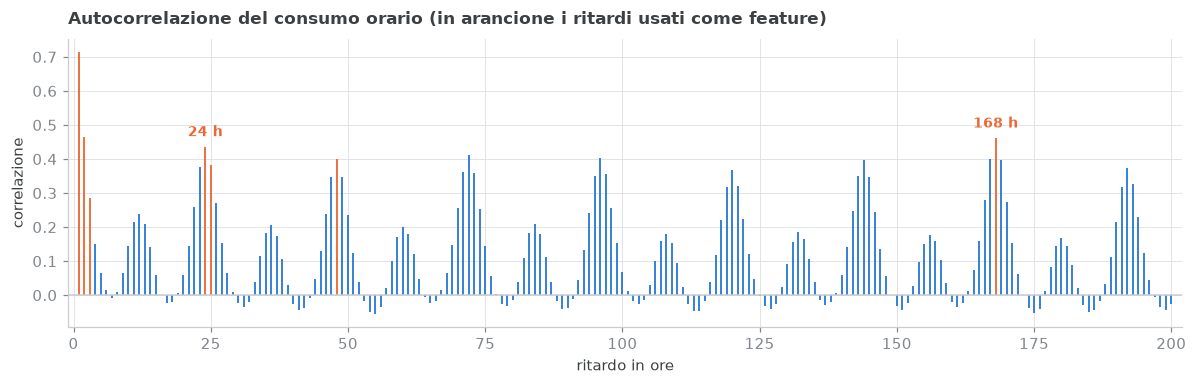

,autocorrelazione
1,0.713
2,0.465
3,0.286
24,0.436
25,0.383
48,0.401
168,0.461


In [10]:
RITARDI = 200
acf = pd.Series({k: serie.autocorr(lag=k) for k in range(1, RITARDI + 1)})

notevoli = [lag for lag in LAGS if 1 <= lag <= RITARDI]
colori = [ARANCIO if k in notevoli else BLU for k in acf.index]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.vlines(acf.index, 0, acf.to_numpy(), color=colori, linewidth=1.2)
ax.axhline(0, color="#c9ccd1", linewidth=1.0)
for k in (24, 168):
    if k in acf.index:
        ax.annotate(
            f"{k} h",
            xy=(k, acf[k]),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            color=ARANCIO,
            fontsize=9,
            fontweight="bold",
        )
ax.set_title("Autocorrelazione del consumo orario (in arancione i ritardi usati come feature)")
ax.set_xlabel("ritardo in ore")
ax.set_ylabel("correlazione")
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

acf.loc[notevoli].round(3).rename("autocorrelazione").to_frame()

L'autocorrelazione decade in poche ore, poi risale con picchi netti ai multipli
di 24 e un picco locale a 168. Non è una scelta estetica: sono i ritardi in cui la
serie somiglia davvero a sé stessa, e sono esattamente quelli nella lista `lags` di
`configs/params.yaml`.

## 5. Stagionalità annuale: perché il test dura 12 mesi

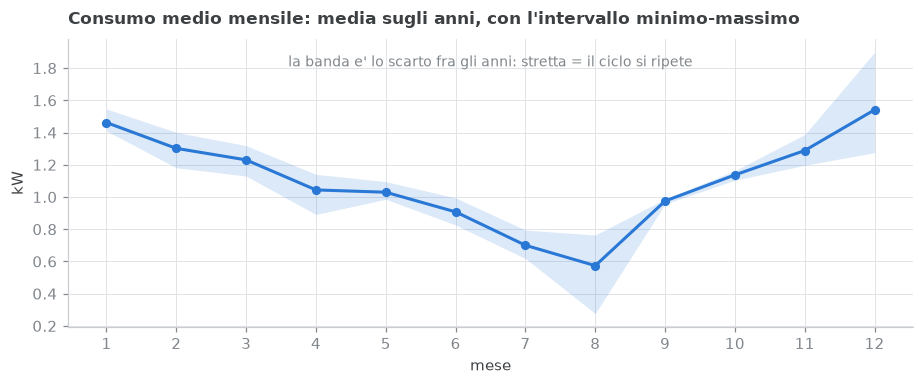

timestamp,2006,2007,2008,2009,2010
timestamp,,,,,
1,NaN,1.55,1.46,1.41,1.43
2,NaN,1.40,1.18,1.25,1.38
3,NaN,1.32,1.25,1.23,1.13
4,NaN,0.89,1.12,1.14,1.03
5,NaN,0.99,1.02,1.01,1.10
6,NaN,0.83,0.99,0.84,0.97
7,NaN,0.67,0.79,0.62,0.72
8,NaN,0.76,0.28,0.66,0.59
9,NaN,0.97,0.99,0.99,0.96


In [11]:
mensile = serie.groupby([serie.index.year, serie.index.month]).mean().unstack(0)
media = mensile.mean(axis=1)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.fill_between(
    mensile.index, mensile.min(axis=1), mensile.max(axis=1), color=BLU, alpha=0.16, linewidth=0
)
ax.plot(mensile.index, media.to_numpy(), color=BLU, marker="o", markersize=5)
ax.set_title("Consumo medio mensile: media sugli anni, con l'intervallo minimo-massimo")
ax.set_xlabel("mese")
ax.set_ylabel("kW")
ax.set_xticks(range(1, 13))
ax.annotate(
    "la banda e' lo scarto fra gli anni: stretta = il ciclo si ripete",
    xy=(6.5, float(mensile.max(axis=1).max())),
    xytext=(0, -2),
    textcoords="offset points",
    ha="center",
    va="top",
    color=TENUE,
    fontsize=9,
)
fig.tight_layout()
plt.show()

# Il dettaglio per anno resta leggibile come tabella: il 2006 contribuisce
# soltanto con dicembre, e il 2010 si ferma a novembre.
mensile.round(2)

Il consumo invernale è circa il doppio di quello estivo, e la banda stretta
dice che il ciclo si ripete: non è l'anomalia di un anno particolare. Un test di
6 mesi cadrebbe interamente dentro mezza stagione e
misurerebbe il modello su un solo regime: con 12 mesi il test contiene un ciclo
completo, e il confronto con i baseline è fatto sulle stesse condizioni che il
modello incontrerebbe in esercizio.

## 6. La matrice delle feature, costruita dal modulo della pipeline

In [12]:
feature = build_features(grezzo[[TARGET]], TARGET, LAGS, FINESTRE)

X1, y1 = supervised_for_horizon(feature, grezzo[TARGET], 1)
X24, y24 = supervised_for_horizon(feature, grezzo[TARGET], 24)

print(f"colonne prodotte : {feature.shape[1]}")
print(f"righe grezze     : {len(grezzo)}")
print()
print(f"h=1  -> X {X1.shape}, y {y1.shape}")
print(f"h=24 -> X {X24.shape}, y {y24.shape}")
print()
print("Le stesse feature servono entrambi gli orizzonti: cambia solo l'allineamento")
print("del target, quindi non vengono ricalcolate 24 volte.")

pd.Series(sorted(feature.columns), name="feature").to_frame()

colonne prodotte : 24
righe grezze     : 34589

h=1  -> X (31616, 24), y (31616,)
h=24 -> X (31440, 24), y (31440,)

Le stesse feature servono entrambi gli orizzonti: cambia solo l'allineamento
del target, quindi non vengono ricalcolate 24 volte.


,feature
0,dayofweek
1,dow_cos
2,dow_sin
3,hour
4,hour_cos
5,hour_sin
6,is_weekend
7,lag_0h
8,lag_168h
9,lag_1h


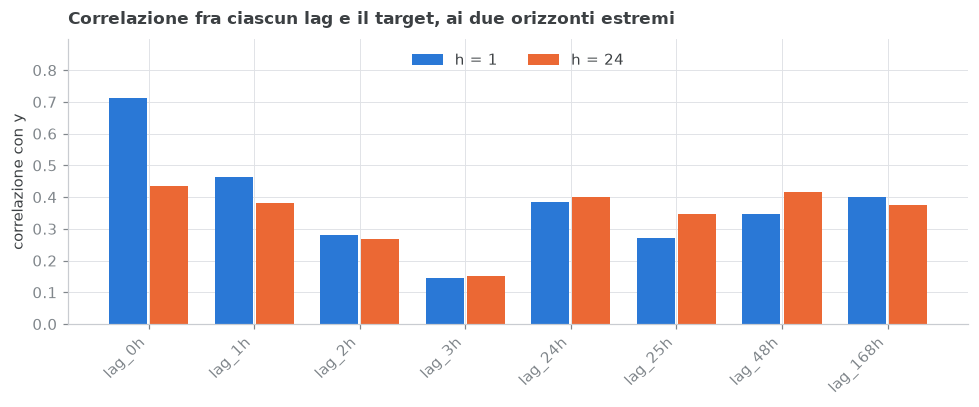

,h = 1,h = 24
lag_0h,0.712,0.436
lag_1h,0.463,0.382
lag_2h,0.282,0.268
lag_3h,0.145,0.151
lag_24h,0.385,0.401
lag_25h,0.271,0.348
lag_48h,0.347,0.415
lag_168h,0.401,0.375


In [13]:
colonne_lag = sorted(
    (c for c in feature.columns if c.startswith("lag_")),
    key=lambda c: int(c.removeprefix("lag_").removesuffix("h")),
)

correlazioni = pd.DataFrame(
    {
        "h = 1": X1[colonne_lag].corrwith(y1),
        "h = 24": X24[colonne_lag].corrwith(y24),
    }
).loc[colonne_lag]

posizioni = np.arange(len(colonne_lag))
larghezza = 0.36
scarto = larghezza / 2 + 0.015  # un filo di superficie fra le due barre della coppia

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(posizioni - scarto, correlazioni["h = 1"], larghezza, color=BLU, label="h = 1")
ax.bar(posizioni + scarto, correlazioni["h = 24"], larghezza, color=ARANCIO, label="h = 24")
ax.set_title("Correlazione fra ciascun lag e il target, ai due orizzonti estremi")
ax.set_xticks(posizioni, colonne_lag, rotation=45, ha="right")
ax.set_ylabel("correlazione con y")
ax.set_ylim(0, float(correlazioni.to_numpy().max()) * 1.26)
ax.legend(loc="upper center", ncols=2)
fig.tight_layout()
plt.show()

correlazioni.round(3)

Questo grafico spiega da solo perché il progetto addestra un modello per
orizzonte invece di uno solo.

A **h = 1** comanda `lag_0h`, l'ultimo valore osservato: previsione a un'ora significa
soprattutto "quanto somiglia a adesso". A **h = 24** il quadro si ridistribuisce, e
`lag_0h` resta alto per una ragione diversa — a ventiquattro ore di distanza *è* la
stessa ora del giorno prima, cioè la stessa informazione che usa il baseline
stagionale. Due regimi diversi, due modelli diversi: un unico modello costretto a
servirli entrambi dovrebbe scendere a compromessi su entrambi.

---

### Cosa giustifica questa analisi

| Scelta nel codice | Evidenza qui |
|---|---|
| `lags: [0, 1, 2, 3, 24, 25, 48, 168]` | i picchi dell'autocorrelazione a 24 e 168 |
| `hour_sin`, `dow_sin`, `is_weekend` | doppio picco quotidiano e scostamento del weekend |
| `test_months: 12` | il ciclo annuale, che 6 mesi taglierebbero a metà |
| copertura dell'88,9 % anziché del 98,7 % | la propagazione dei buchi sulla finestra storica |
| un modello per orizzonte | la ridistribuzione delle correlazioni fra h=1 e h=24 |